In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
import folium
from folium.plugins import HeatMap, MarkerCluster
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [2]:
df = pd.read_csv("../data/raw/karachi_crime_dataset.csv")

In [3]:
df.head

<bound method NDFrame.head of            INCIDENT_ID          TOWN TOWN_RISK_LEVEL  TOWN_PRIORITY_RANK  \
0      INCIDENT_000001    Lyari Town            High                   1   
1      INCIDENT_000002    Lyari Town            High                   1   
2      INCIDENT_000003    Lyari Town            High                   1   
3      INCIDENT_000004    Lyari Town            High                   1   
4      INCIDENT_000005    Lyari Town            High                   1   
...                ...           ...             ...                 ...   
99995  INCIDENT_099996  Korangi Town            High                   1   
99996  INCIDENT_099997  Korangi Town            High                   1   
99997  INCIDENT_099998  Korangi Town            High                   1   
99998  INCIDENT_099999  Korangi Town            High                   1   
99999  INCIDENT_100000  Korangi Town            High                   1   

        SUBDIVISION SUBDIVISION_RISK_LEVEL  SUBDIVISION_P

In [4]:
df.info

<bound method DataFrame.info of            INCIDENT_ID          TOWN TOWN_RISK_LEVEL  TOWN_PRIORITY_RANK  \
0      INCIDENT_000001    Lyari Town            High                   1   
1      INCIDENT_000002    Lyari Town            High                   1   
2      INCIDENT_000003    Lyari Town            High                   1   
3      INCIDENT_000004    Lyari Town            High                   1   
4      INCIDENT_000005    Lyari Town            High                   1   
...                ...           ...             ...                 ...   
99995  INCIDENT_099996  Korangi Town            High                   1   
99996  INCIDENT_099997  Korangi Town            High                   1   
99997  INCIDENT_099998  Korangi Town            High                   1   
99998  INCIDENT_099999  Korangi Town            High                   1   
99999  INCIDENT_100000  Korangi Town            High                   1   

        SUBDIVISION SUBDIVISION_RISK_LEVEL  SUBDIVISION

In [5]:
df.describe()

,TOWN_PRIORITY_RANK,SUBDIVISION_PRIORITY_RANK,SEVERITY_SCORE,LATITUDE,LONGITUDE,IS_RED_ZONE,IS_ORANGE_ZONE,IS_YELLOW_ZONE,IS_GREEN_ZONE,IS_WHITE_ZONE,RANK
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000
mean,2.203660,1.781620,7.465630,24.894634,67.064546,0.40670,0.056070,0.348910,0.188320,0.0,3.216040
std,1.253139,0.739821,2.353545,0.060245,0.074175,0.49122,0.230058,0.476628,0.390969,0.0,6.886952
min,1.000000,1.000000,1.000000,24.550000,66.961173,0.00000,0.000000,0.000000,0.000000,0.0,0.000000
25%,1.000000,1.000000,6.000000,24.856500,67.002435,0.00000,0.000000,0.000000,0.000000,0.0,0.000000
50%,2.000000,2.000000,8.000000,24.887151,67.056074,0.00000,0.000000,0.000000,0.000000,0.0,0.000000
75%,4.000000,2.000000,10.000000,24.936899,67.120100,1.00000,0.000000,1.000000,0.000000,0.0,1.000000
max,4.000000,3.000000,10.000000,25.077030,67.366157,1.00000,1.000000,1.000000,1.000000,0.0,30.000000


In [6]:
df.isnull().sum()

INCIDENT_ID                  0
TOWN                         0
TOWN_RISK_LEVEL              0
TOWN_PRIORITY_RANK           0
SUBDIVISION                  0
SUBDIVISION_RISK_LEVEL       0
SUBDIVISION_PRIORITY_RANK    0
SEVERITY_SCORE               0
SEVERITY                     0
DATE                         0
LATITUDE                     0
LONGITUDE                    0
CRIME_TYPE                   0
IS_RED_ZONE                  0
IS_ORANGE_ZONE               0
IS_YELLOW_ZONE               0
IS_GREEN_ZONE                0
IS_WHITE_ZONE                0
RISK_ZONE                    0
SOURCE                       0
RANK                         0
dtype: int64

In [7]:
(df.isnull().sum() /len(df))*100

INCIDENT_ID                  0.0
TOWN                         0.0
TOWN_RISK_LEVEL              0.0
TOWN_PRIORITY_RANK           0.0
SUBDIVISION                  0.0
SUBDIVISION_RISK_LEVEL       0.0
SUBDIVISION_PRIORITY_RANK    0.0
SEVERITY_SCORE               0.0
SEVERITY                     0.0
DATE                         0.0
LATITUDE                     0.0
LONGITUDE                    0.0
CRIME_TYPE                   0.0
IS_RED_ZONE                  0.0
IS_ORANGE_ZONE               0.0
IS_YELLOW_ZONE               0.0
IS_GREEN_ZONE                0.0
IS_WHITE_ZONE                0.0
RISK_ZONE                    0.0
SOURCE                       0.0
RANK                         0.0
dtype: float64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df = df.drop_duplicates()

In [10]:
df = df.dropna()

In [11]:
df["LATITUDE"] = df["LATITUDE"].fillna(df["LATITUDE"].mean())

In [12]:
df.dtypes

INCIDENT_ID                      str
TOWN                             str
TOWN_RISK_LEVEL                  str
TOWN_PRIORITY_RANK             int64
SUBDIVISION                      str
SUBDIVISION_RISK_LEVEL           str
SUBDIVISION_PRIORITY_RANK      int64
SEVERITY_SCORE                 int64
SEVERITY                         str
DATE                             str
LATITUDE                     float64
LONGITUDE                    float64
CRIME_TYPE                       str
IS_RED_ZONE                    int64
IS_ORANGE_ZONE                 int64
IS_YELLOW_ZONE                 int64
IS_GREEN_ZONE                  int64
IS_WHITE_ZONE                  int64
RISK_ZONE                        str
SOURCE                           str
RANK                           int64
dtype: object

In [13]:
df.nunique()

INCIDENT_ID                  100000
TOWN                             18
TOWN_RISK_LEVEL                   3
TOWN_PRIORITY_RANK                4
SUBDIVISION                     194
SUBDIVISION_RISK_LEVEL            4
SUBDIVISION_PRIORITY_RANK         3
SEVERITY_SCORE                   10
SEVERITY                          3
DATE                           1826
LATITUDE                        161
LONGITUDE                       161
CRIME_TYPE                       27
IS_RED_ZONE                       2
IS_ORANGE_ZONE                    2
IS_YELLOW_ZONE                    2
IS_GREEN_ZONE                     2
IS_WHITE_ZONE                     1
RISK_ZONE                         4
SOURCE                            1
RANK                             26
dtype: int64

In [14]:
print("Total Columns:", len(df.columns))

for column in df.columns:
    print(column)

Total Columns: 21
INCIDENT_ID
TOWN
TOWN_RISK_LEVEL
TOWN_PRIORITY_RANK
SUBDIVISION
SUBDIVISION_RISK_LEVEL
SUBDIVISION_PRIORITY_RANK
SEVERITY_SCORE
SEVERITY
DATE
LATITUDE
LONGITUDE
CRIME_TYPE
IS_RED_ZONE
IS_ORANGE_ZONE
IS_YELLOW_ZONE
IS_GREEN_ZONE
IS_WHITE_ZONE
RISK_ZONE
SOURCE
RANK


In [15]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values

,Missing Values,Missing Percentage
INCIDENT_ID,0,0.0
TOWN,0,0.0
TOWN_RISK_LEVEL,0,0.0
TOWN_PRIORITY_RANK,0,0.0
SUBDIVISION,0,0.0
SUBDIVISION_RISK_LEVEL,0,0.0
SUBDIVISION_PRIORITY_RANK,0,0.0
SEVERITY_SCORE,0,0.0
SEVERITY,0,0.0
DATE,0,0.0


In [16]:
# ==========================================
# CATEGORICAL DATA ANALYSIS
# ==========================================

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

print("Categorical Columns:")

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts().head(10))

Categorical Columns:

INCIDENT_ID:
INCIDENT_ID
INCIDENT_000001    1
INCIDENT_000002    1
INCIDENT_000003    1
INCIDENT_000004    1
INCIDENT_000005    1
INCIDENT_000006    1
INCIDENT_000007    1
INCIDENT_000008    1
INCIDENT_000009    1
INCIDENT_000010    1
Name: count, dtype: int64

TOWN:
TOWN
Orangi Town             11501
Lyari Town              11149
Korangi Town             8354
Landhi Town              8124
Gulshan-e-Iqbal Town     6974
Saddar Town              6728
Gulberg Town             5810
Baldia Town              5686
Jamshed Town             5104
Keamari Town             4789
Name: count, dtype: int64

TOWN_RISK_LEVEL:
TOWN_RISK_LEVEL
High      48889
Medium    31327
Low       19784
Name: count, dtype: int64

SUBDIVISION:
SUBDIVISION
Baghdadi          2143
Kalakot           2077
Zaman Town        1745
Shah Baig Line    1392
Nasir Colony      1383
Nayabad           1347
Landhi 89         1311
Singo Lane        1303
Pirabad           1282
Regal Chowk       1247
Name: count, dt

In [17]:
# ==========================================
# NUMERICAL COLUMNS ANALYSIS
# ==========================================

numerical_columns = df.select_dtypes(
    include=np.number
).columns

print("Numerical Columns:")

for column in numerical_columns:
    print(f"{column}: {df[column].nunique()} unique values")

Numerical Columns:
TOWN_PRIORITY_RANK: 4 unique values
SUBDIVISION_PRIORITY_RANK: 3 unique values
SEVERITY_SCORE: 10 unique values
LATITUDE: 161 unique values
LONGITUDE: 161 unique values
IS_RED_ZONE: 2 unique values
IS_ORANGE_ZONE: 2 unique values
IS_YELLOW_ZONE: 2 unique values
IS_GREEN_ZONE: 2 unique values
IS_WHITE_ZONE: 1 unique values
RANK: 26 unique values


In [18]:
# ==========================================
# CRIME TYPE DISTRIBUTION
# ==========================================

if "CRIME_TYPE" in df.columns:
    crime_counts = df["CRIME_TYPE"].value_counts()

    print(crime_counts)
else:
    print("CRIME_TYPE column not found.")

CRIME_TYPE
Robbery                10269
Snatching              10051
Murder                  8138
Theft                   7634
Gang Violence           7247
Political Violence      5970
Assault                 5907
Drug Possession         5706
Homicide                5668
Gang Activity           5370
Land Grabbing           5269
Extortion               5255
Kidnapping              5234
Industrial Hazards      5009
Shootings                944
Gun Violence             821
Cellphone Snatching      757
Street Crimes            674
Drug Mafia Activity      657
Mugging                  641
Targeted Killing         613
Industrial Theft         517
Street Snatching         398
Ethnic Conflict          390
Phone Theft              388
Violence                 349
Mobile Snatching         124
Name: count, dtype: int64


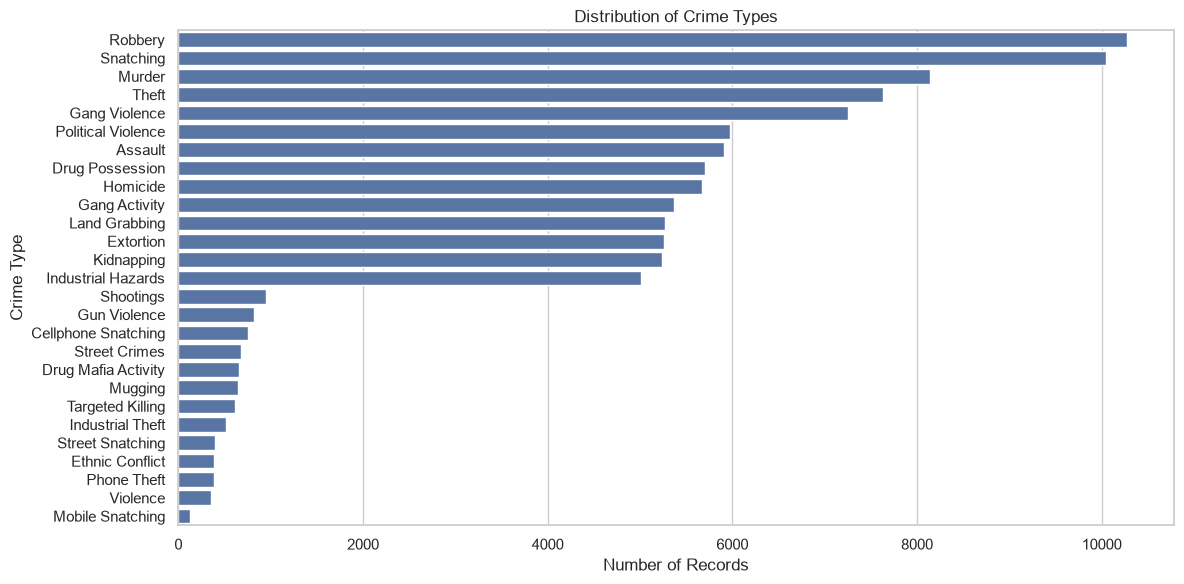

In [19]:
# ==========================================
# CRIME TYPE DISTRIBUTION PLOT
# ==========================================

if "CRIME_TYPE" in df.columns:
    plt.figure(figsize=(12, 6))

    sns.countplot(
        data=df,
        y="CRIME_TYPE",
        order=df["CRIME_TYPE"].value_counts().index
    )

    plt.title("Distribution of Crime Types")
    plt.xlabel("Number of Records")
    plt.ylabel("Crime Type")
    plt.tight_layout()
    plt.show()

In [20]:
# ==========================================
# CRIME SEVERITY ANALYSIS
# ==========================================

if "SEVERITY" in df.columns:
    print(df["SEVERITY"].value_counts())
else:
    print("SEVERITY column not found.")

SEVERITY
High      55111
Medium    31752
Low       13137
Name: count, dtype: int64


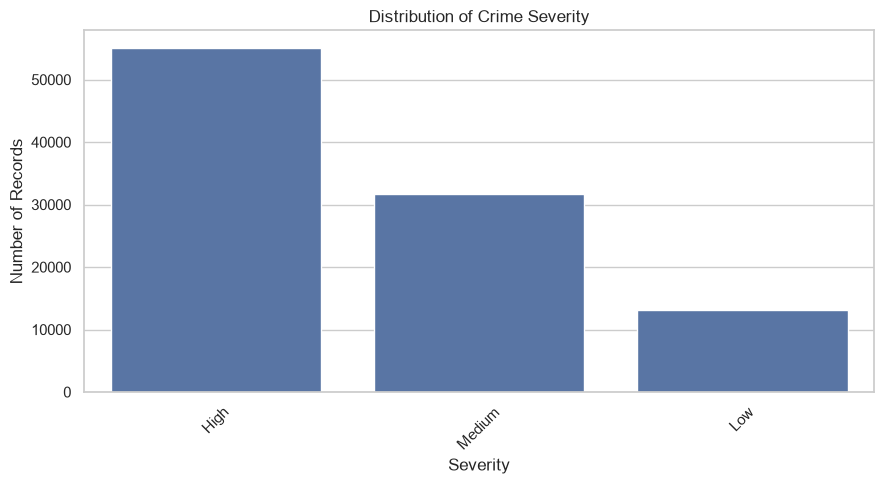

In [21]:
# ==========================================
# CRIME SEVERITY DISTRIBUTION PLOT
# ==========================================

if "SEVERITY" in df.columns:
    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x="SEVERITY",
        order=df["SEVERITY"].value_counts().index
    )

    plt.title("Distribution of Crime Severity")
    plt.xlabel("Severity")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [22]:
# ==========================================
# GEOGRAPHICAL COLUMN IDENTIFICATION
# ==========================================

print("Available Columns:")
print(df.columns.tolist())

Available Columns:
['INCIDENT_ID', 'TOWN', 'TOWN_RISK_LEVEL', 'TOWN_PRIORITY_RANK', 'SUBDIVISION', 'SUBDIVISION_RISK_LEVEL', 'SUBDIVISION_PRIORITY_RANK', 'SEVERITY_SCORE', 'SEVERITY', 'DATE', 'LATITUDE', 'LONGITUDE', 'CRIME_TYPE', 'IS_RED_ZONE', 'IS_ORANGE_ZONE', 'IS_YELLOW_ZONE', 'IS_GREEN_ZONE', 'IS_WHITE_ZONE', 'RISK_ZONE', 'SOURCE', 'RANK']


In [23]:
# ==========================================
# LATITUDE AND LONGITUDE ANALYSIS
# ==========================================

# Update these names if your dataset uses different column names
LAT_COL = "LATITUDE"
LON_COL = "LONGITUDE"

print("Latitude Column:", LAT_COL)
print("Longitude Column:", LON_COL)

print("\nLatitude Statistics:")
print(df[LAT_COL].describe())

print("\nLongitude Statistics:")
print(df[LON_COL].describe())

Latitude Column: LATITUDE
Longitude Column: LONGITUDE

Latitude Statistics:
count    100000.000000
mean         24.894634
std           0.060245
min          24.550000
25%          24.856500
50%          24.887151
75%          24.936899
max          25.077030
Name: LATITUDE, dtype: float64

Longitude Statistics:
count    100000.000000
mean         67.064546
std           0.074175
min          66.961173
25%          67.002435
50%          67.056074
75%          67.120100
max          67.366157
Name: LONGITUDE, dtype: float64


In [24]:
# ==========================================
# MISSING GEOGRAPHICAL VALUES
# ==========================================

print("Missing Latitude:", df[LAT_COL].isnull().sum())
print("Missing Longitude:", df[LON_COL].isnull().sum())

print("Total Missing Coordinates:",
      df[[LAT_COL, LON_COL]].isnull().any(axis=1).sum())

Missing Latitude: 0
Missing Longitude: 0
Total Missing Coordinates: 0


In [25]:
# ==========================================
# GEOGRAPHICAL COORDINATE VALIDATION
# ==========================================

valid_coordinates = (
    df[LAT_COL].between(-90, 90) &
    df[LON_COL].between(-180, 180)
)

print("Valid Coordinates:", valid_coordinates.sum())
print("Invalid Coordinates:", (~valid_coordinates).sum())

Valid Coordinates: 100000
Invalid Coordinates: 0


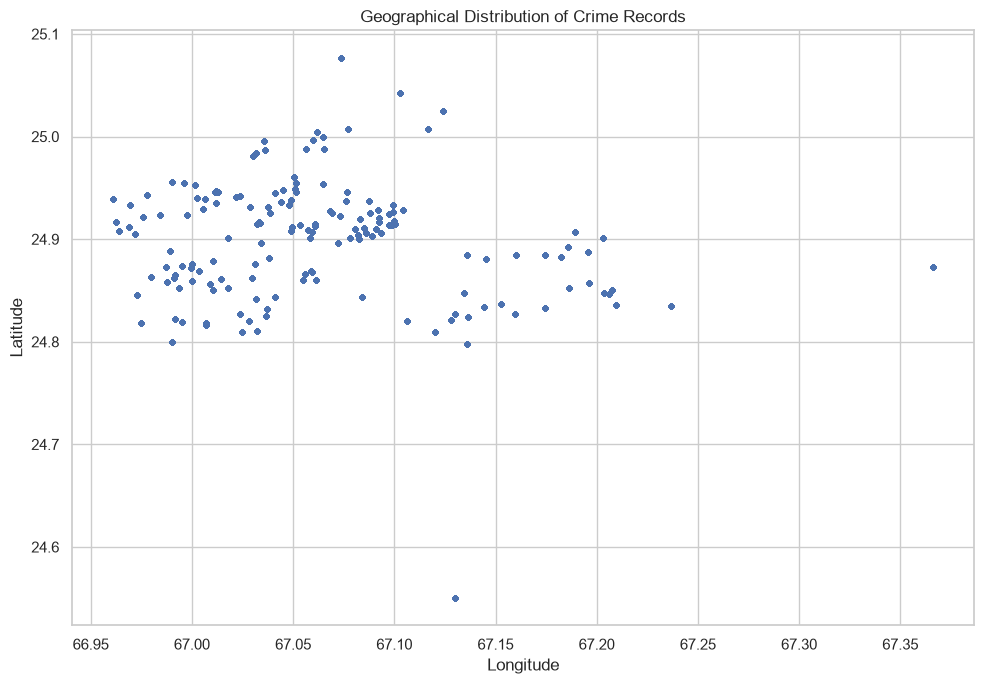

In [26]:
# ==========================================
# CRIME LOCATIONS SCATTER PLOT
# ==========================================

plt.figure(figsize=(10, 7))

plt.scatter(
    df[LON_COL],
    df[LAT_COL],
    alpha=0.4,
    s=10
)

plt.title("Geographical Distribution of Crime Records")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# CREATE WORKING DATASET
# ==========================================

crime_df = df.copy()

print("Working dataset created successfully!")
print("Original Shape:", df.shape)
print("Working Shape:", crime_df.shape)

Working dataset created successfully!
Original Shape: (100000, 21)
Working Shape: (100000, 21)


In [28]:
# ==========================================
# CONVERT COORDINATES TO NUMERIC
# ==========================================

crime_df[LAT_COL] = pd.to_numeric(
    crime_df[LAT_COL], errors="coerce"
)

crime_df[LON_COL] = pd.to_numeric(
    crime_df[LON_COL], errors="coerce"
)

print("Coordinate data types converted successfully!")

Coordinate data types converted successfully!


In [29]:
# ==========================================
# HANDLE MISSING COORDINATES
# ==========================================

crime_df = crime_df.dropna(
    subset=[LAT_COL, LON_COL]
).copy()

print("Shape after removing missing coordinates:", crime_df.shape)

Shape after removing missing coordinates: (100000, 21)


In [30]:
# ==========================================
# REMOVE INVALID COORDINATES
# ==========================================

valid_mask = (
    crime_df[LAT_COL].between(-90, 90) &
    crime_df[LON_COL].between(-180, 180)
)

crime_df = crime_df[valid_mask].copy()

print("Shape after coordinate validation:", crime_df.shape)

Shape after coordinate validation: (100000, 21)


In [31]:
# ==========================================
# CHECK DUPLICATE COORDINATES
# ==========================================

duplicate_coordinates = crime_df.duplicated(
    subset=[LAT_COL, LON_COL]
).sum()

print("Duplicate Coordinate Records:", duplicate_coordinates)

Duplicate Coordinate Records: 99839


In [32]:
# ==========================================
# PREPARE GEOGRAPHICAL DATA FOR DBSCAN
# ==========================================

coordinates = crime_df[[LAT_COL, LON_COL]].to_numpy()

print("DBSCAN Input Shape:", coordinates.shape)
print("Ready for geographical clustering!")

DBSCAN Input Shape: (100000, 2)
Ready for geographical clustering!


In [33]:
# ==========================================
# CONVERT COORDINATES TO RADIANS
# ==========================================

coordinates_rad = np.radians(
    crime_df[[LAT_COL, LON_COL]].to_numpy()
)

EARTH_RADIUS_KM = 6371.0

print("Coordinates converted into radians!")
print("Coordinate Shape:", coordinates_rad.shape)

Coordinates converted into radians!
Coordinate Shape: (100000, 2)


In [34]:
# ==========================================
# DBSCAN INITIAL PARAMETERS
# ==========================================

MIN_SAMPLES = 5

print("Minimum Samples:", MIN_SAMPLES)

Minimum Samples: 5


In [35]:
# ==========================================
# K-DISTANCE CALCULATION
# ==========================================

neighbors = NearestNeighbors(
    n_neighbors=MIN_SAMPLES,
    metric="haversine",
    algorithm="ball_tree"
)

neighbors.fit(coordinates_rad)

distances, indices = neighbors.kneighbors(coordinates_rad)

k_distances = np.sort(
    distances[:, MIN_SAMPLES - 1] * EARTH_RADIUS_KM
)

print("K-Distance calculation completed!")

K-Distance calculation completed!


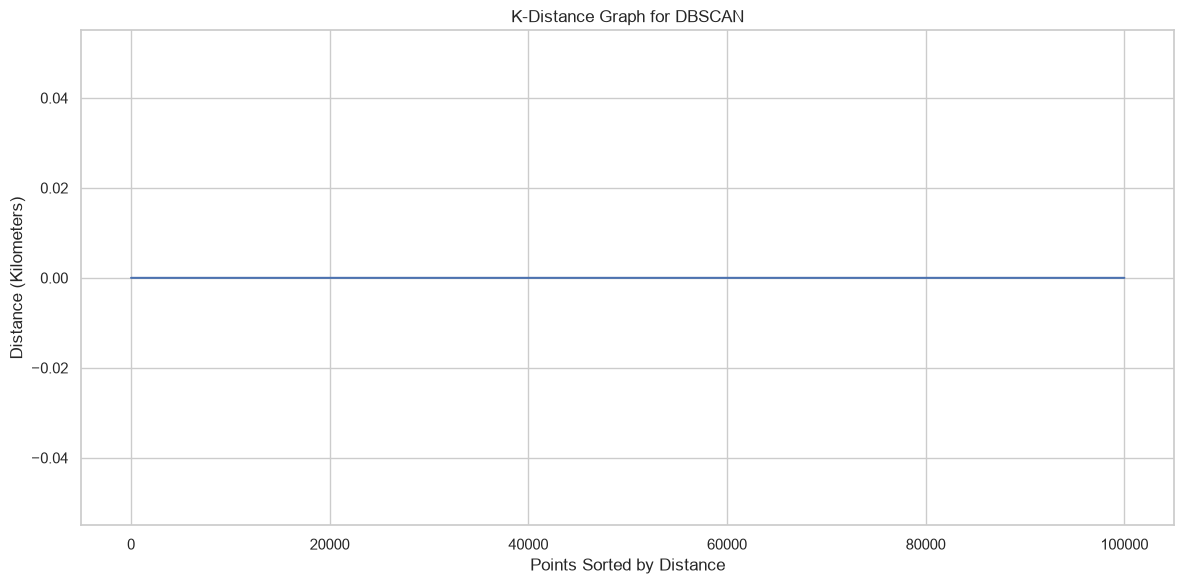

In [36]:
# ==========================================
# K-DISTANCE GRAPH FOR EPS SELECTION
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(k_distances)

plt.title("K-Distance Graph for DBSCAN")
plt.xlabel("Points Sorted by Distance")
plt.ylabel("Distance (Kilometers)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [37]:
# ==========================================
# K-DISTANCE STATISTICS
# ==========================================

print("Minimum Distance:", round(k_distances.min(), 4), "km")
print("Median Distance:", round(np.median(k_distances), 4), "km")
print("Maximum Distance:", round(k_distances.max(), 4), "km")

Minimum Distance: 0.0 km
Median Distance: 0.0 km
Maximum Distance: 0.0 km


In [38]:
# ==========================================
# DBSCAN PARAMETERS
# ==========================================

EPS_KM = 0.5  # Temporary starting value; adjust using K-distance graph
MIN_SAMPLES = 5

print("EPS:", EPS_KM, "KM")
print("Minimum Samples:", MIN_SAMPLES)

EPS: 0.5 KM
Minimum Samples: 5


In [39]:
# ==========================================
# APPLY DBSCAN CLUSTERING
# ==========================================

dbscan_model = DBSCAN(
    eps=EPS_KM / EARTH_RADIUS_KM,
    min_samples=MIN_SAMPLES,
    metric="haversine",
    algorithm="ball_tree"
)

crime_df["CLUSTER"] = dbscan_model.fit_predict(coordinates_rad)

print("DBSCAN clustering completed successfully!")

DBSCAN clustering completed successfully!


In [40]:
# ==========================================
# CLUSTER COUNT ANALYSIS
# ==========================================

cluster_labels = crime_df["CLUSTER"]

total_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels.values else 0)

noise_points = (cluster_labels == -1).sum()

print("Total Crime Hotspots:", total_clusters)
print("Noise Points:", noise_points)
print("Total Records:", len(crime_df))

Total Crime Hotspots: 130
Noise Points: 0
Total Records: 100000


In [41]:
# ==========================================
# CLUSTER DISTRIBUTION
# ==========================================

cluster_distribution = (
    crime_df["CLUSTER"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Crime Records")
)

cluster_distribution

,Cluster,Crime Records
0,0,2143
1,1,4181
2,2,1347
3,3,2061
4,4,316
...,...,...
125,125,176
126,126,236
127,127,225
128,128,240


In [42]:
# ==========================================
# CRIME HOTSPOT SUMMARY
# ==========================================

hotspot_summary = (
    crime_df[crime_df["CLUSTER"] != -1]
    .groupby("CLUSTER")
    .agg(
        Crime_Records=(LAT_COL, "size"),
        Center_Latitude=(LAT_COL, "mean"),
        Center_Longitude=(LON_COL, "mean")
    )
    .reset_index()
    .sort_values("Crime_Records", ascending=False)
)

hotspot_summary

,CLUSTER,Crime_Records,Center_Latitude,Center_Longitude
1,1,4181,24.871792,67.001687
26,26,3569,24.946264,67.012448
81,81,3356,24.937149,67.087613
52,52,2962,24.881096,67.145214
0,0,2143,24.859200,66.999800
...,...,...,...,...
83,83,199,24.922359,67.073089
88,88,194,24.919989,67.083197
110,110,187,24.961012,67.050185
108,108,185,24.953549,67.064879


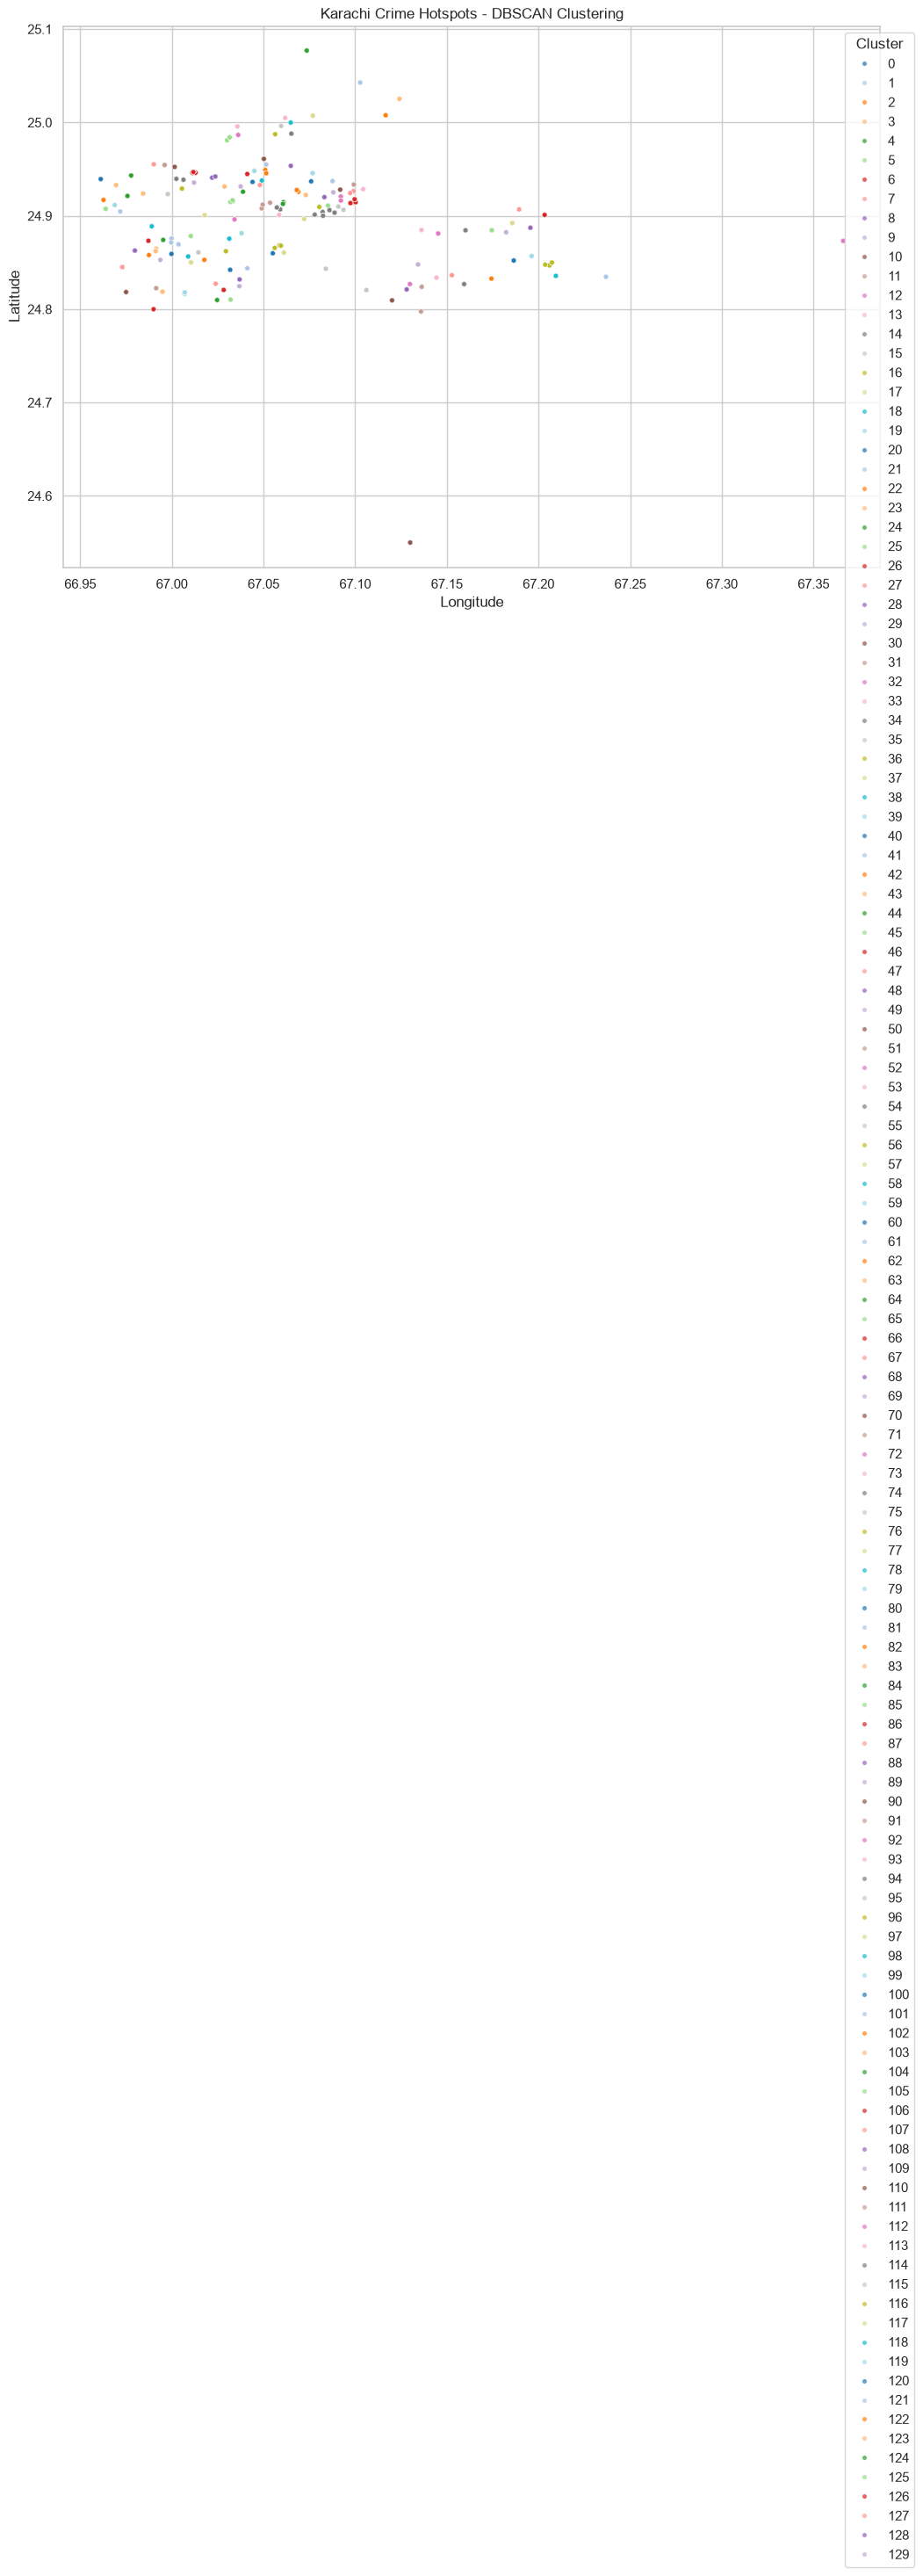

In [43]:
# ==========================================
# DBSCAN CLUSTER VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=crime_df,
    x=LON_COL,
    y=LAT_COL,
    hue="CLUSTER",
    palette="tab20",
    s=15,
    alpha=0.7,
    legend="full"
)

plt.title("Karachi Crime Hotspots - DBSCAN Clustering")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [44]:
# ==========================================
# TOP 10 CRIME HOTSPOTS
# ==========================================

top_hotspots = hotspot_summary.head(10)

top_hotspots

,CLUSTER,Crime_Records,Center_Latitude,Center_Longitude
1,1,4181,24.871792,67.001687
26,26,3569,24.946264,67.012448
81,81,3356,24.937149,67.087613
52,52,2962,24.881096,67.145214
0,0,2143,24.859200,66.999800
16,16,2087,24.847706,67.206026
3,3,2061,24.863880,66.991382
20,20,1889,24.852093,67.186472
7,7,1745,24.836298,67.152710
86,86,1709,24.914725,67.099347


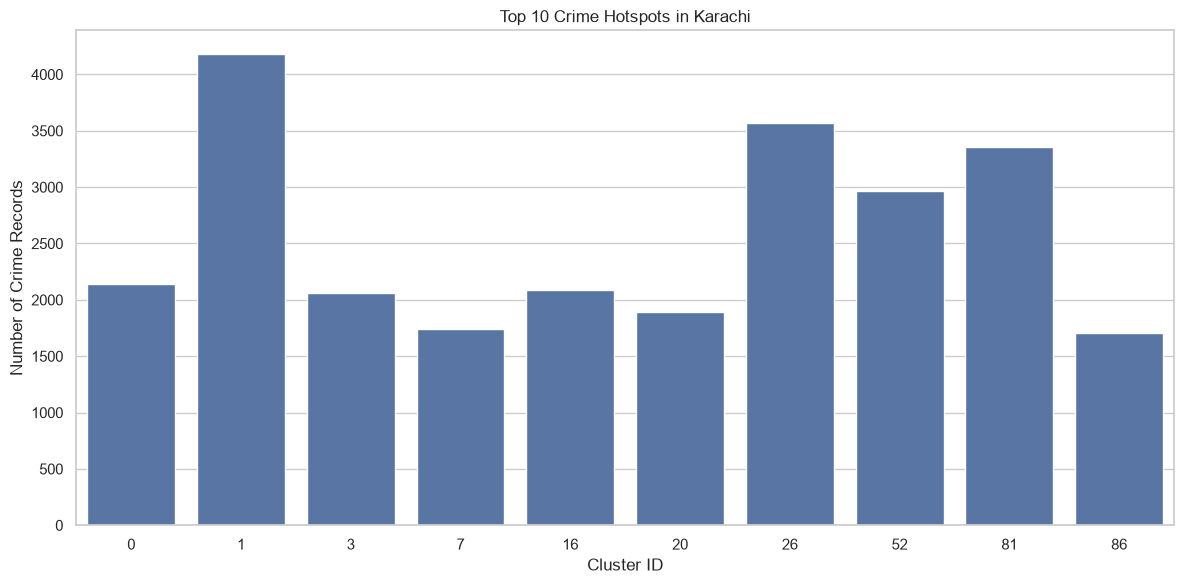

In [45]:
# ==========================================
# TOP 10 HOTSPOTS VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_hotspots,
    x="CLUSTER",
    y="Crime_Records"
)

plt.title("Top 10 Crime Hotspots in Karachi")
plt.xlabel("Cluster ID")
plt.ylabel("Number of Crime Records")
plt.tight_layout()
plt.show()

In [46]:
# ==========================================
# SAVE CLUSTERED DATA
# ==========================================

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Sirf zaroori columns rakho taake file chhoti rahe
wanted_columns = [
    "LATITUDE", "LONGITUDE", "TOWN", "SUBDIVISION",
    "CRIME_TYPE_CLEAN", "SEVERITY", "DATE", "CLUSTER"
]
save_columns = [c for c in wanted_columns if c in crime_df.columns]

crime_df[save_columns].to_csv(
    OUTPUT_DIR / "dbscan_crime_results.csv",
    index=False
)

hotspot_summary.to_csv(
    OUTPUT_DIR / "hotspot_summary.csv",
    index=False
)

print("DBSCAN results saved successfully!")
print("Saved columns:", save_columns)

DBSCAN results saved successfully!
Saved columns: ['LATITUDE', 'LONGITUDE', 'TOWN', 'SUBDIVISION', 'SEVERITY', 'DATE', 'CLUSTER']


In [47]:
# ==========================================
# INITIALIZE INTERACTIVE CRIME MAP
# ==========================================

map_center = [
    crime_df[LAT_COL].mean(),
    crime_df[LON_COL].mean()
]

crime_map = folium.Map(
    location=map_center,
    zoom_start=11,
    tiles="OpenStreetMap"
)

print("Interactive map initialized successfully!")

Interactive map initialized successfully!


In [48]:
# ==========================================
# ADD HOTSPOT MARKERS
# ==========================================

for _, row in hotspot_summary.iterrows():

    popup_text = f"""
    <b>Hotspot ID:</b> {row['CLUSTER']}<br>
    <b>Crime Records:</b> {row['Crime_Records']}<br>
    <b>Latitude:</b> {row['Center_Latitude']:.5f}<br>
    <b>Longitude:</b> {row['Center_Longitude']:.5f}
    """

    folium.CircleMarker(
        location=[
            row["Center_Latitude"],
            row["Center_Longitude"]
        ],
        radius=8,
        popup=folium.Popup(popup_text, max_width=250),
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=0.7
    ).add_to(crime_map)

print("Hotspot markers added successfully!")

Hotspot markers added successfully!


In [49]:
# ==========================================
# ADD CRIME DENSITY HEATMAP
# ==========================================

map_data = crime_df[[LAT_COL, LON_COL]].dropna()

# Sample records to keep the map responsive
map_sample = map_data.sample(
    n=min(5000, len(map_data)),
    random_state=42
)

heat_data = map_sample.values.tolist()

HeatMap(
    heat_data,
    name="Crime Density Heatmap",
    radius=15,
    blur=10
).add_to(crime_map)

folium.LayerControl().add_to(crime_map)

print("Crime heatmap layer added successfully!")

Crime heatmap layer added successfully!


In [50]:
# ==========================================
# SAVE INTERACTIVE CRIME MAP
# ==========================================

MAP_DIR = Path("../outputs/maps")
MAP_DIR.mkdir(parents=True, exist_ok=True)

MAP_PATH = MAP_DIR / "crime_hotspot_map.html"

crime_map.save(str(MAP_PATH))

print("Interactive map saved successfully!")
print("File Location:", MAP_PATH)

Interactive map saved successfully!
File Location: ..\outputs\maps\crime_hotspot_map.html


In [51]:
# ==========================================
# NOISE POINTS ANALYSIS
# ==========================================

total_records = len(crime_df)
noise_records = (crime_df["CLUSTER"] == -1).sum()

noise_percentage = (noise_records / total_records) * 100

print("Total Records:", total_records)
print("Noise Records:", noise_records)
print("Noise Percentage:", round(noise_percentage, 2), "%")

Total Records: 100000
Noise Records: 0
Noise Percentage: 0.0 %


In [52]:
# ==========================================
# CLUSTER SIZE DISTRIBUTION
# ==========================================

cluster_sizes = (
    crime_df[crime_df["CLUSTER"] != -1]
    ["CLUSTER"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Largest Cluster:", cluster_sizes.max())
print("Smallest Cluster:", cluster_sizes.min())
print("Average Cluster Size:", round(cluster_sizes.mean(), 2))

cluster_sizes.head(10)

Largest Cluster: 4181
Smallest Cluster: 176
Average Cluster Size: 769.23


CLUSTER
1     4181
26    3569
81    3356
52    2962
0     2143
16    2087
3     2061
20    1889
7     1745
86    1709
Name: count, dtype: int64

In [53]:
from pathlib import Path

project_dir = Path.cwd().parent

app_file = project_dir / "app.py"

app_file.touch(exist_ok=True)

print("File created:", app_file)

File created: C:\Users\kk\OneDrive\Desktop\Crime_Hotspot_Finder\app.py


In [54]:
print(df["SOURCE"].unique())
print("Lat 24.55 wali rows:", (df["LATITUDE"] == 24.55).sum())
print(df.groupby(["LATITUDE", "LONGITUDE"]).size().describe())

<ArrowStringArray>
['Synthetic']
Length: 1, dtype: str
Lat 24.55 wali rows: 562
count     161.000000
mean      621.118012
std       510.204804
min       164.000000
25%       237.000000
50%       480.000000
75%       833.000000
max      3356.000000
dtype: float64


In [55]:
type_map = {
    "Homicide": "Murder",
    "Mobile Snatching": "Snatching", "Cellphone Snatching": "Snatching",
    "Street Snatching": "Snatching", "Phone Theft": "Snatching",
    "Shootings": "Gun Violence", "Targeted Killing": "Murder",
    "Gang Activity": "Gang Violence",
}
crime_df["CRIME_TYPE_CLEAN"] = crime_df["CRIME_TYPE"].replace(type_map)
print(crime_df["CRIME_TYPE_CLEAN"].nunique(), "crime types")

19 crime types


In [56]:
locs = (
    crime_df.groupby(["LATITUDE", "LONGITUDE"])
    .agg(crime_count=("INCIDENT_ID", "size"))
    .reset_index()
)
X = np.radians(locs[["LATITUDE", "LONGITUDE"]].to_numpy())
w = locs["crime_count"].to_numpy()
print(locs.shape)   

(161, 3)


In [57]:
from sklearn.metrics import roc_curve, roc_auc_score


EPS_KM = 1
MIN_SAMPLES = 500
# ----------------------------------------------------------------------

# Cell A: data  train (2020-2023) and test (2024-2025) 
crime_df["DATE"] = pd.to_datetime(crime_df["DATE"])
train = crime_df[crime_df["DATE"] < "2024-01-01"]
test = crime_df[crime_df["DATE"] >= "2024-01-01"]

keys = ["LATITUDE", "LONGITUDE"]
tr = train.groupby(keys).size().rename("count_train").reset_index()
te = test.groupby(keys).size().rename("count_test").reset_index()
print(len(train), "train records |", len(test), "test records")

# Cell B: train data DBSCAN
Xtr = np.radians(tr[keys].to_numpy())
tr["CLUSTER"] = DBSCAN(
    eps=EPS_KM / 6371.0, min_samples=MIN_SAMPLES, metric="haversine"
).fit_predict(Xtr, sample_weight=tr["count_train"].to_numpy())

cluster_total = tr[tr["CLUSTER"] != -1].groupby("CLUSTER")["count_train"].sum()
tr["hotspot_score"] = tr["CLUSTER"].map(cluster_total).fillna(0)
print("Hotspots (train):", tr[tr["CLUSTER"] != -1]["CLUSTER"].nunique())

# Cell C: labels and AUC
data = tr.merge(te, on=keys, how="outer").fillna(
    {"count_train": 0, "count_test": 0, "hotspot_score": 0}
)
threshold = data["count_test"].quantile(0.75)
y_true = (data["count_test"] >= threshold).astype(int)

auc = roc_auc_score(y_true, data["hotspot_score"])
fpr, tpr, _ = roc_curve(y_true, data["hotspot_score"])
print("DBSCAN hotspot AUC:", round(auc, 3))

71464 train records | 28536 test records
Hotspots (train): 42
DBSCAN hotspot AUC: 0.591


In [58]:
print("Noise locations:", (tr["CLUSTER"] == -1).sum(), "/", len(tr))
print(tr["hotspot_score"].describe())

Noise locations: 34 / 161
count     161.000000
mean     2211.993789
std      2230.160968
min         0.000000
25%       604.000000
50%      1881.000000
75%      3718.000000
max      7953.000000
Name: hotspot_score, dtype: float64


In [59]:
print(data[["count_train", "count_test"]].corr())

             count_train  count_test
count_train     1.000000    0.993783
count_test      0.993783    1.000000


In [60]:
rows = []
for eps_km in [0.5, 1, 2]:
    for ms in [500, 1000, 2000]:
        lab = DBSCAN(eps=eps_km / 6371.0, min_samples=ms,
                     metric="haversine").fit_predict(
            Xtr, sample_weight=tr["count_train"].to_numpy())

        tmp = tr[keys + ["count_train"]].copy()
        tmp["CLUSTER"] = lab
        tot = tmp[tmp["CLUSTER"] != -1].groupby("CLUSTER")["count_train"].sum()
        tmp["score_cluster"] = tmp["CLUSTER"].map(tot).fillna(0)
        tmp["score_location"] = np.where(lab != -1, tmp["count_train"], 0)

        d = tmp.merge(te, on=keys, how="outer").fillna(
            {"count_train": 0, "count_test": 0,
             "score_cluster": 0, "score_location": 0})
        y = (d["count_test"] >= d["count_test"].quantile(0.75)).astype(int)

        rows.append({
            "eps_km": eps_km, "min_samples": ms,
            "hotspots": len(set(lab)) - (1 if -1 in lab else 0),
            "noise_locations": int((lab == -1).sum()),
            "noise_crimes_%": round(tmp.loc[lab == -1, "count_train"].sum()
                                    / tmp["count_train"].sum() * 100, 1),
            "AUC_cluster_total": round(roc_auc_score(y, d["score_cluster"]), 3),
            "AUC_location": round(roc_auc_score(y, d["score_location"]), 3),
        })

sens_table = pd.DataFrame(rows)
sens_table

,eps_km,min_samples,hotspots,noise_locations,noise_crimes_%,AUC_cluster_total,AUC_location
0,0.5,500,54,83,29.2,0.857,0.997
1,0.5,1000,14,134,68.4,0.618,0.635
2,0.5,2000,4,153,86.0,0.548,0.550
3,1.0,500,42,34,13.0,0.591,0.997
4,1.0,1000,18,77,38.0,0.578,0.747
5,1.0,2000,9,110,59.3,0.585,0.624
6,2.0,500,14,4,2.2,0.355,0.997
7,2.0,1000,10,12,8.1,0.365,0.855
8,2.0,2000,7,37,19.6,0.407,0.826


Hotspots: 10
DBSCAN hotspot AUC: 0.855


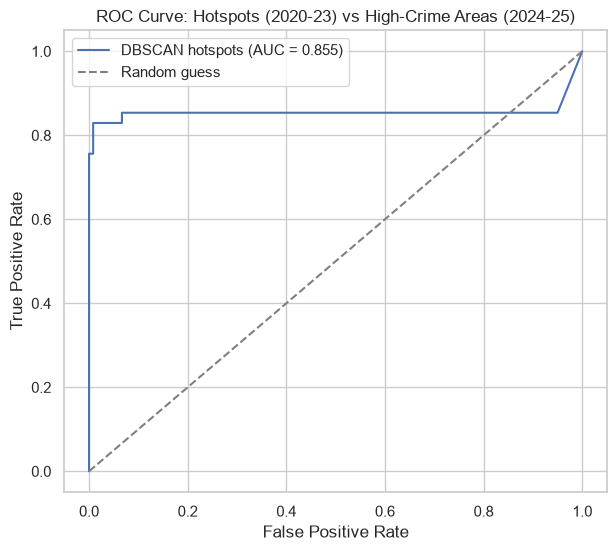

In [61]:
EPS_KM = 2.0
MIN_SAMPLES = 1000

Xtr = np.radians(tr[keys].to_numpy())
tr["CLUSTER"] = DBSCAN(
    eps=EPS_KM / 6371.0, min_samples=MIN_SAMPLES, metric="haversine"
).fit_predict(Xtr, sample_weight=tr["count_train"].to_numpy())

tr["hotspot_score"] = np.where(tr["CLUSTER"] != -1, tr["count_train"], 0)

data = tr.merge(te, on=keys, how="outer").fillna(
    {"count_train": 0, "count_test": 0, "hotspot_score": 0}
)
y_true = (data["count_test"] >= data["count_test"].quantile(0.75)).astype(int)

auc = roc_auc_score(y_true, data["hotspot_score"])
fpr, tpr, _ = roc_curve(y_true, data["hotspot_score"])
print("Hotspots:", tr[tr["CLUSTER"] != -1]["CLUSTER"].nunique())
print("DBSCAN hotspot AUC:", round(auc, 3))

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"DBSCAN hotspots (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Hotspots (2020-23) vs High-Crime Areas (2024-25)")
plt.legend()
plt.grid(True)
plt.savefig("../outputs/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [62]:
   locs = (
       crime_df.groupby(["LATITUDE", "LONGITUDE"])
       .agg(crime_count=("INCIDENT_ID", "size"))
       .reset_index()
   )
   X = np.radians(locs[["LATITUDE", "LONGITUDE"]].to_numpy())
   w = locs["crime_count"].to_numpy()

   locs["CLUSTER"] = DBSCAN(
       eps=EPS_KM / 6371.0, min_samples=MIN_SAMPLES, metric="haversine"
   ).fit_predict(X, sample_weight=w)

   crime_df = crime_df.drop(columns="CLUSTER", errors="ignore").merge(
       locs[["LATITUDE", "LONGITUDE", "CLUSTER"]],
       on=["LATITUDE", "LONGITUDE"], how="left"
   )
   labels = crime_df["CLUSTER"].to_numpy()
   print(crime_df["CLUSTER"].value_counts().head())

CLUSTER
 1    60030
 0     8925
 5     7200
-1     6659
 2     6050
Name: count, dtype: int64


In [63]:
sens_table.to_csv("../outputs/parameter_sensitivity.csv", index=False)

In [64]:
  mask = locs["CLUSTER"].to_numpy() != -1
  number_of_clusters = len(set(locs.loc[mask, "CLUSTER"]))
  evaluation_data = X[mask]
  silhouette = silhouette_score(X[mask], locs.loc[mask, "CLUSTER"].to_numpy(),metric="haversine")
  noise_records = (crime_df["CLUSTER"] == -1).sum()
  noise_percentage = noise_records / len(crime_df) * 100
  print("Clusters:", number_of_clusters, "| Silhouette:", round(silhouette, 4))

Clusters: 9 | Silhouette: 0.0238


In [65]:
# ==========================================
# SAVE DBSCAN EVALUATION REPORT
# ==========================================

evaluation_report = {
    "Total Records": total_records,
    "Total Clusters": number_of_clusters,
    "Noise Records": int(noise_records),
    "Noise Percentage": round(noise_percentage, 2),
    "EPS (KM)": EPS_KM,
    "MIN SAMPLES": MIN_SAMPLES,
    "Silhouette Score": round(silhouette, 4),
    "ROC AUC (2020-23 vs 2024-25)": round(auc, 3),
    "Data Type": "Synthetic",
}

evaluation_df = pd.DataFrame(
    list(evaluation_report.items()), columns=["Metric", "Value"]
)

evaluation_df

,Metric,Value
0,Total Records,100000
1,Total Clusters,9
2,Noise Records,6659
3,Noise Percentage,6.66
4,EPS (KM),2.0
5,MIN SAMPLES,1000
6,Silhouette Score,0.0238
7,ROC AUC (2020-23 vs 2024-25),0.855
8,Data Type,Synthetic


In [66]:
# ==========================================
# EXPORT EVALUATION REPORT
# ==========================================

evaluation_df.to_csv(
    OUTPUT_DIR / "dbscan_evaluation_report.csv",
    index=False
)

print("Evaluation report saved successfully!")

Evaluation report saved successfully!


In [67]:
!python -m streamlit run ../app.py

^C
